#Program 1
Using Python, preprocess a high-dimensional housing dataset with continuous,
discrete, ordinal, and nominal variables by handling missing values, duplicates, and
outliers. Apply Min-Max normalization and Z-score standardization, and generate bar
plots and box plots. Generate histograms and scatter plots before and after
normalization to compare the changes in data distribution, scale, and relationships.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load housing dataset
try:
    df = pd.read_csv('/content/Housing.csv')
    print("Dataset loaded successfully!")
    print(f"Dataset Shape: {df.shape}")
    print("Columns:", df.columns.tolist())
    display(df.head())
except Exception as e:
    print("Error loading dataset:", e)


Dataset loaded successfully!
Dataset Shape: (545, 13)
Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


## Data Cleaning: Handling Duplicates, Missing Values, and Outliers

In [ ]:
# 1. Handle Duplicates
print(df.duplicated())
df = df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")

# 2. Handle Missing Values
# Continuous columns in the new dataset: fill with median
df['area'] = df['area'].fillna(df['area'].median())
df['price'] = df['price'].fillna(df['price'].median())

# 3. Handle Outliers using IQR method for continuous variables
for col in ['area', 'price']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Cap outliers to the upper/lower bounds
    df[col] = np.clip(df[col], lower_bound, upper_bound)

print("Missing values and outliers handled successfully for 'area' and 'price'.")

0      False
1      False
2      False
3      False
4      False
       ...  
540    False
541    False
542    False
543    False
544    False
Length: 545, dtype: bool
Shape after removing duplicates: (545, 13)
Missing values and outliers handled successfully for 'area' and 'price'.


## Feature Encoding & Visualizations

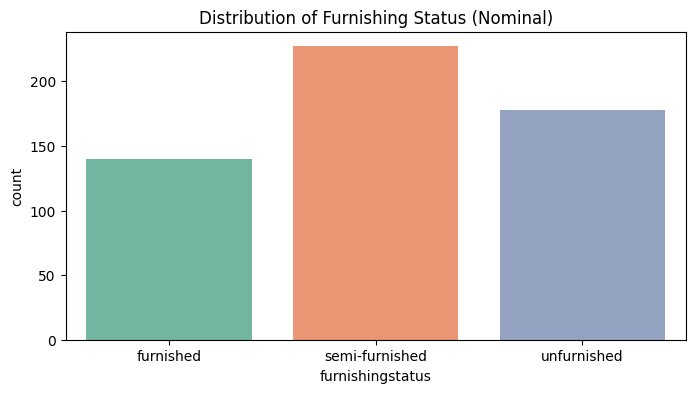

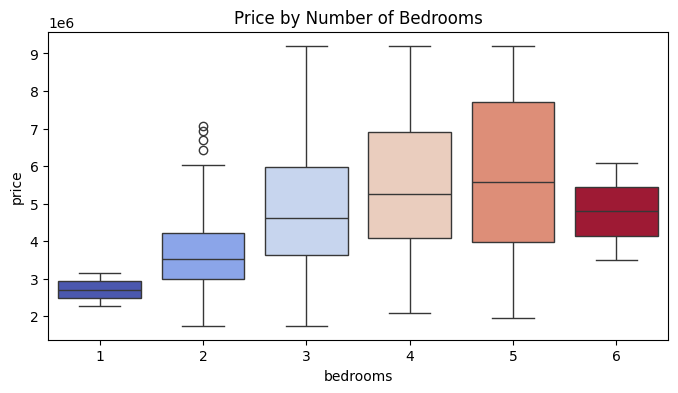

In [ ]:
# Bar plot for Nominal Variable (furnishingstatus)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='furnishingstatus', palette='Set2', hue='furnishingstatus', legend=False)
plt.title('Distribution of Furnishing Status (Nominal)')
plt.show()

# Box plot of price by bedrooms (Discrete/Ordinal category)
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='bedrooms', y='price', palette='coolwarm', hue='bedrooms', legend=False)
plt.title('Price by Number of Bedrooms')
plt.show()

## Scaling: Min-Max Normalization and Z-score Standardization

In [ ]:
# We will apply scaling to our continuous variables
scaling_cols = ['area', 'price']

# Min-Max Normalization
min_max_scaler = MinMaxScaler()
df_minmax = df.copy()
df_minmax[scaling_cols] = min_max_scaler.fit_transform(df[scaling_cols])

# Z-score Standardization
std_scaler = StandardScaler()
df_zscore = df.copy()
df_zscore[scaling_cols] = std_scaler.fit_transform(df[scaling_cols])

## Comparing Data Distributions (Before vs. After Scaling)

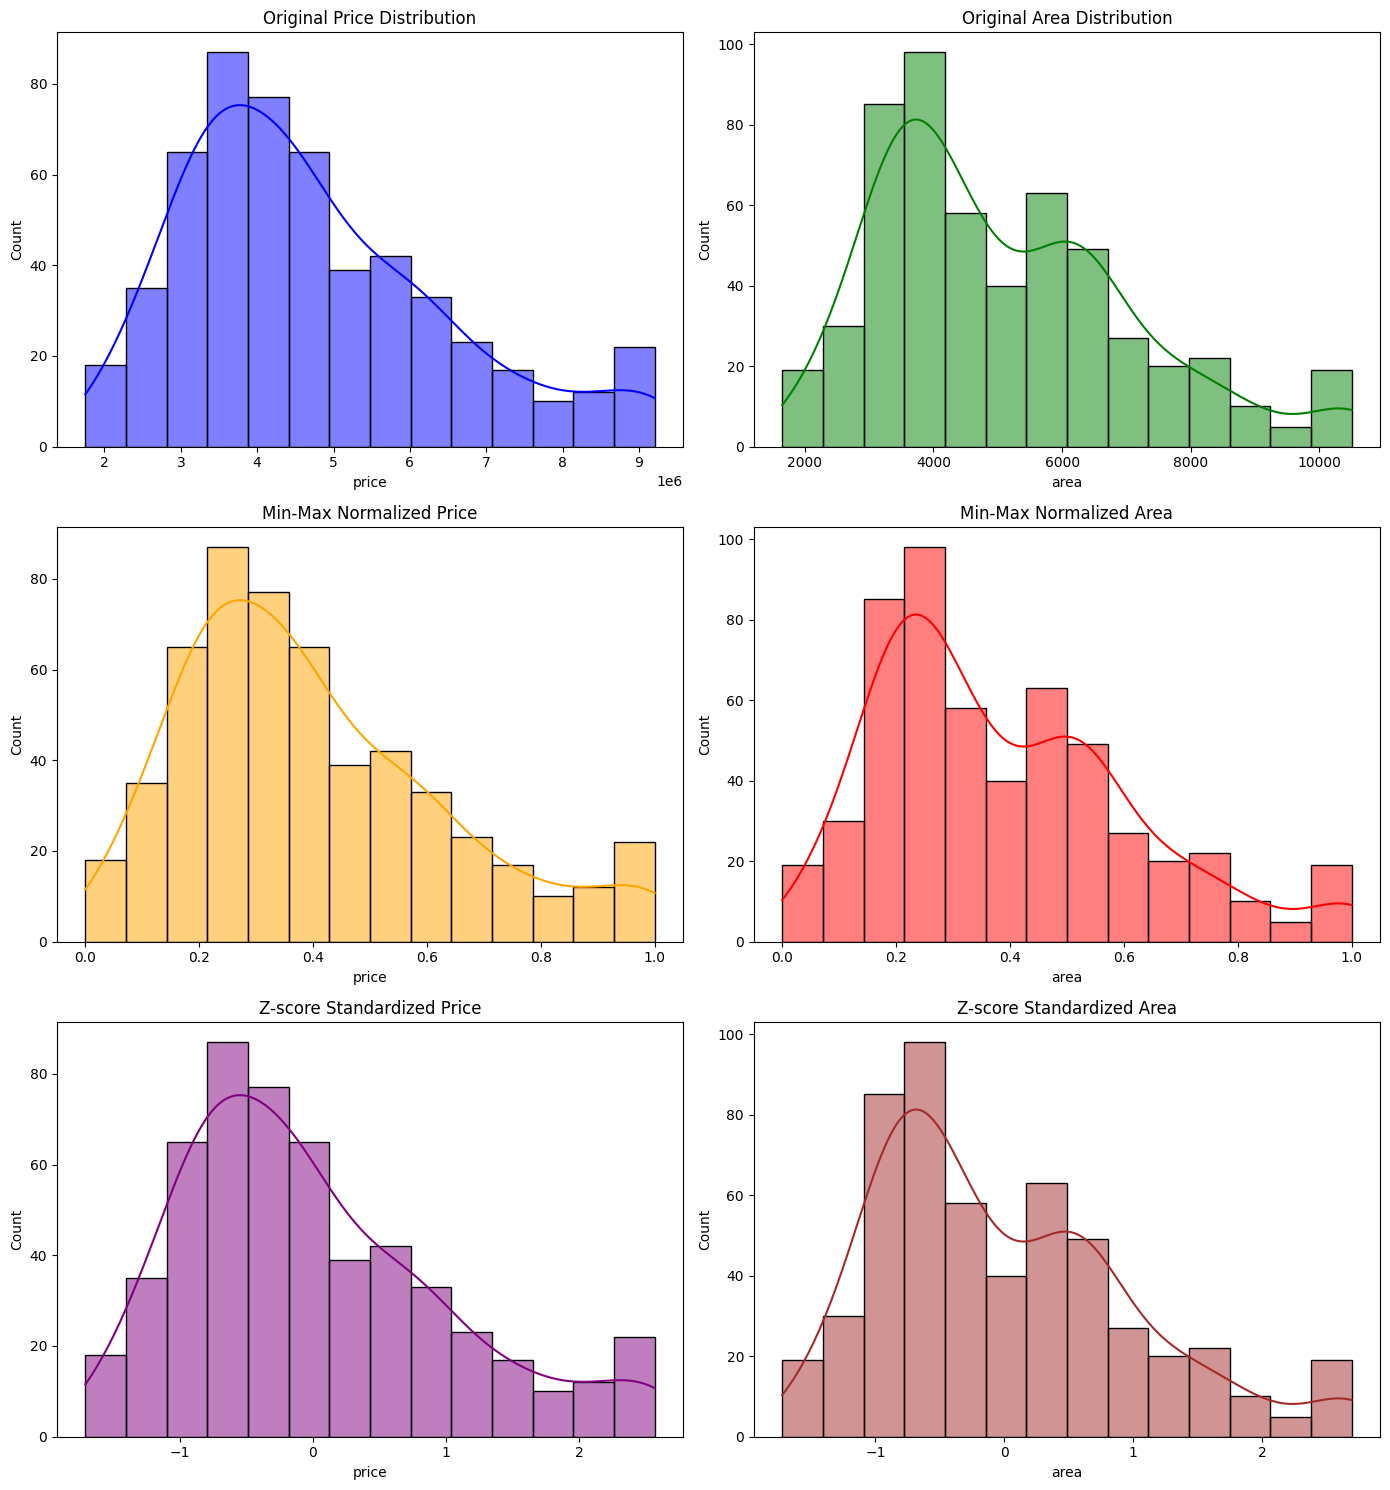

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# Original Histograms
sns.histplot(df['price'], ax=axes[0, 0], kde=True, color='blue')
axes[0, 0].set_title('Original Price Distribution')
sns.histplot(df['area'], ax=axes[0, 1], kde=True, color='green')
axes[0, 1].set_title('Original Area Distribution')

# Min-Max Normalized Histograms
sns.histplot(df_minmax['price'], ax=axes[1, 0], kde=True, color='orange')
axes[1, 0].set_title('Min-Max Normalized Price')
sns.histplot(df_minmax['area'], ax=axes[1, 1], kde=True, color='red')
axes[1, 1].set_title('Min-Max Normalized Area')

# Z-score Standardized Histograms
sns.histplot(df_zscore['price'], ax=axes[2, 0], kde=True, color='purple')
axes[2, 0].set_title('Z-score Standardized Price')
sns.histplot(df_zscore['area'], ax=axes[2, 1], kde=True, color='brown')
axes[2, 1].set_title('Z-score Standardized Area')

plt.tight_layout()
plt.show()

## Comparing Relationships (Scatter Plots Before vs. After Scaling)

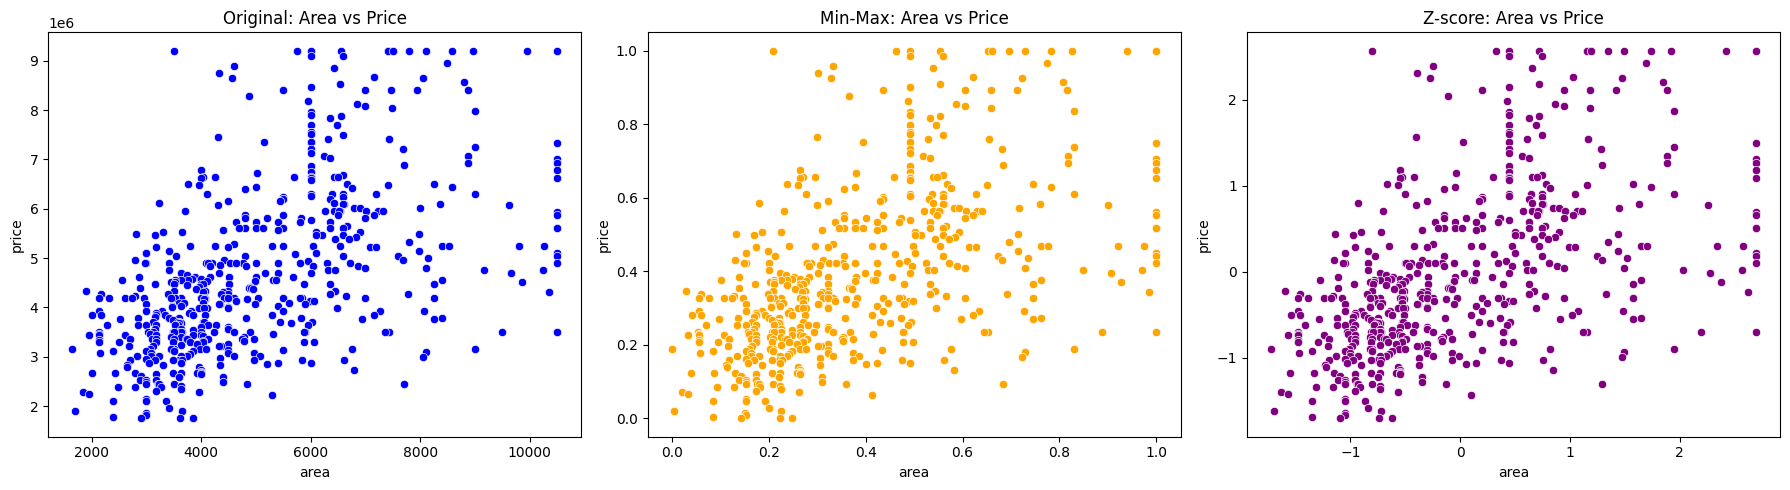

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original relationship
sns.scatterplot(data=df, x='area', y='price', ax=axes[0], color='blue')
axes[0].set_title('Original: Area vs Price')

# Min-Max scaling relationship
sns.scatterplot(data=df_minmax, x='area', y='price', ax=axes[1], color='orange')
axes[1].set_title('Min-Max: Area vs Price')

# Z-score standardization relationship
sns.scatterplot(data=df_zscore, x='area', y='price', ax=axes[2], color='purple')
axes[2].set_title('Z-score: Area vs Price')

plt.tight_layout()
plt.show()

## Processing the New Dataset: housePrice.csv
Now we will prepare, clean, normalize, and visualize the variables from the `housePrice.csv` dataset.

In [ ]:
# 1. Reload & Check Columns
df_new = pd.read_csv('/content/housePrice.csv')

# 2. Handle Duplicates
df_new = df_new.drop_duplicates()
print(f"Shape after removing duplicates: {df_new.shape}")

# 3. Convert 'Area' column to numeric, removing commas or invalid characters if any
df_new['Area'] = pd.to_numeric(df_new['Area'].astype(str).str.replace(',', '').str.strip(), errors='coerce')

# 4. Handle Missing Values
df_new['Area'] = df_new['Area'].fillna(df_new['Area'].median())
df_new['Price'] = df_new['Price'].fillna(df_new['Price'].median())

# 5. Handle Outliers using IQR method
for col in ['Area', 'Price']:
    Q1 = df_new[col].quantile(0.25)
    Q3 = df_new[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_new[col] = np.clip(df_new[col], lower_bound, upper_bound)

print("Data cleaning completed successfully. Columns 'Area' and 'Price' are ready.")

Shape after removing duplicates: (3271, 8)
Data cleaning completed successfully. Columns 'Area' and 'Price' are ready.


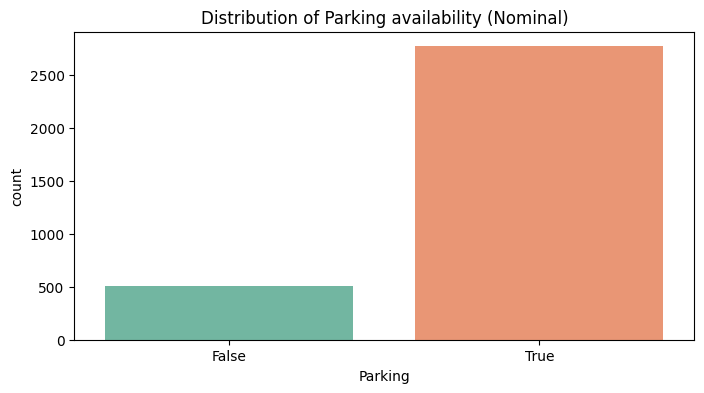

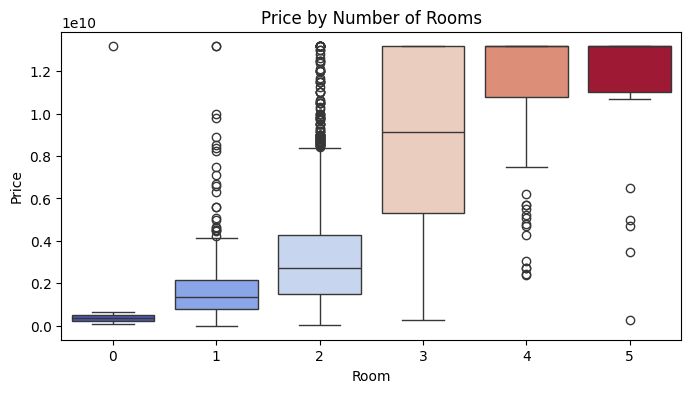

In [ ]:
# Categorical & Discrete Variable Visualizations
# Bar plot for 'Parking' (nominal/discrete)
plt.figure(figsize=(8, 4))
sns.countplot(data=df_new, x='Parking', palette='Set2', hue='Parking', legend=False)
plt.title('Distribution of Parking availability (Nominal)')
plt.show()

# Box plot of Price by Room count
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_new, x='Room', y='Price', palette='coolwarm', hue='Room', legend=False)
plt.title('Price by Number of Rooms')
plt.show()

In [ ]:
# Normalization & Standardization on 'Area' and 'Price'
scaling_cols = ['Area', 'Price']

# Min-Max Normalization
min_max_scaler = MinMaxScaler()
df_new_minmax = df_new.copy()
df_new_minmax[scaling_cols] = min_max_scaler.fit_transform(df_new[scaling_cols])

# Z-score Standardization
std_scaler = StandardScaler()
df_new_zscore = df_new.copy()
df_new_zscore[scaling_cols] = std_scaler.fit_transform(df_new[scaling_cols])

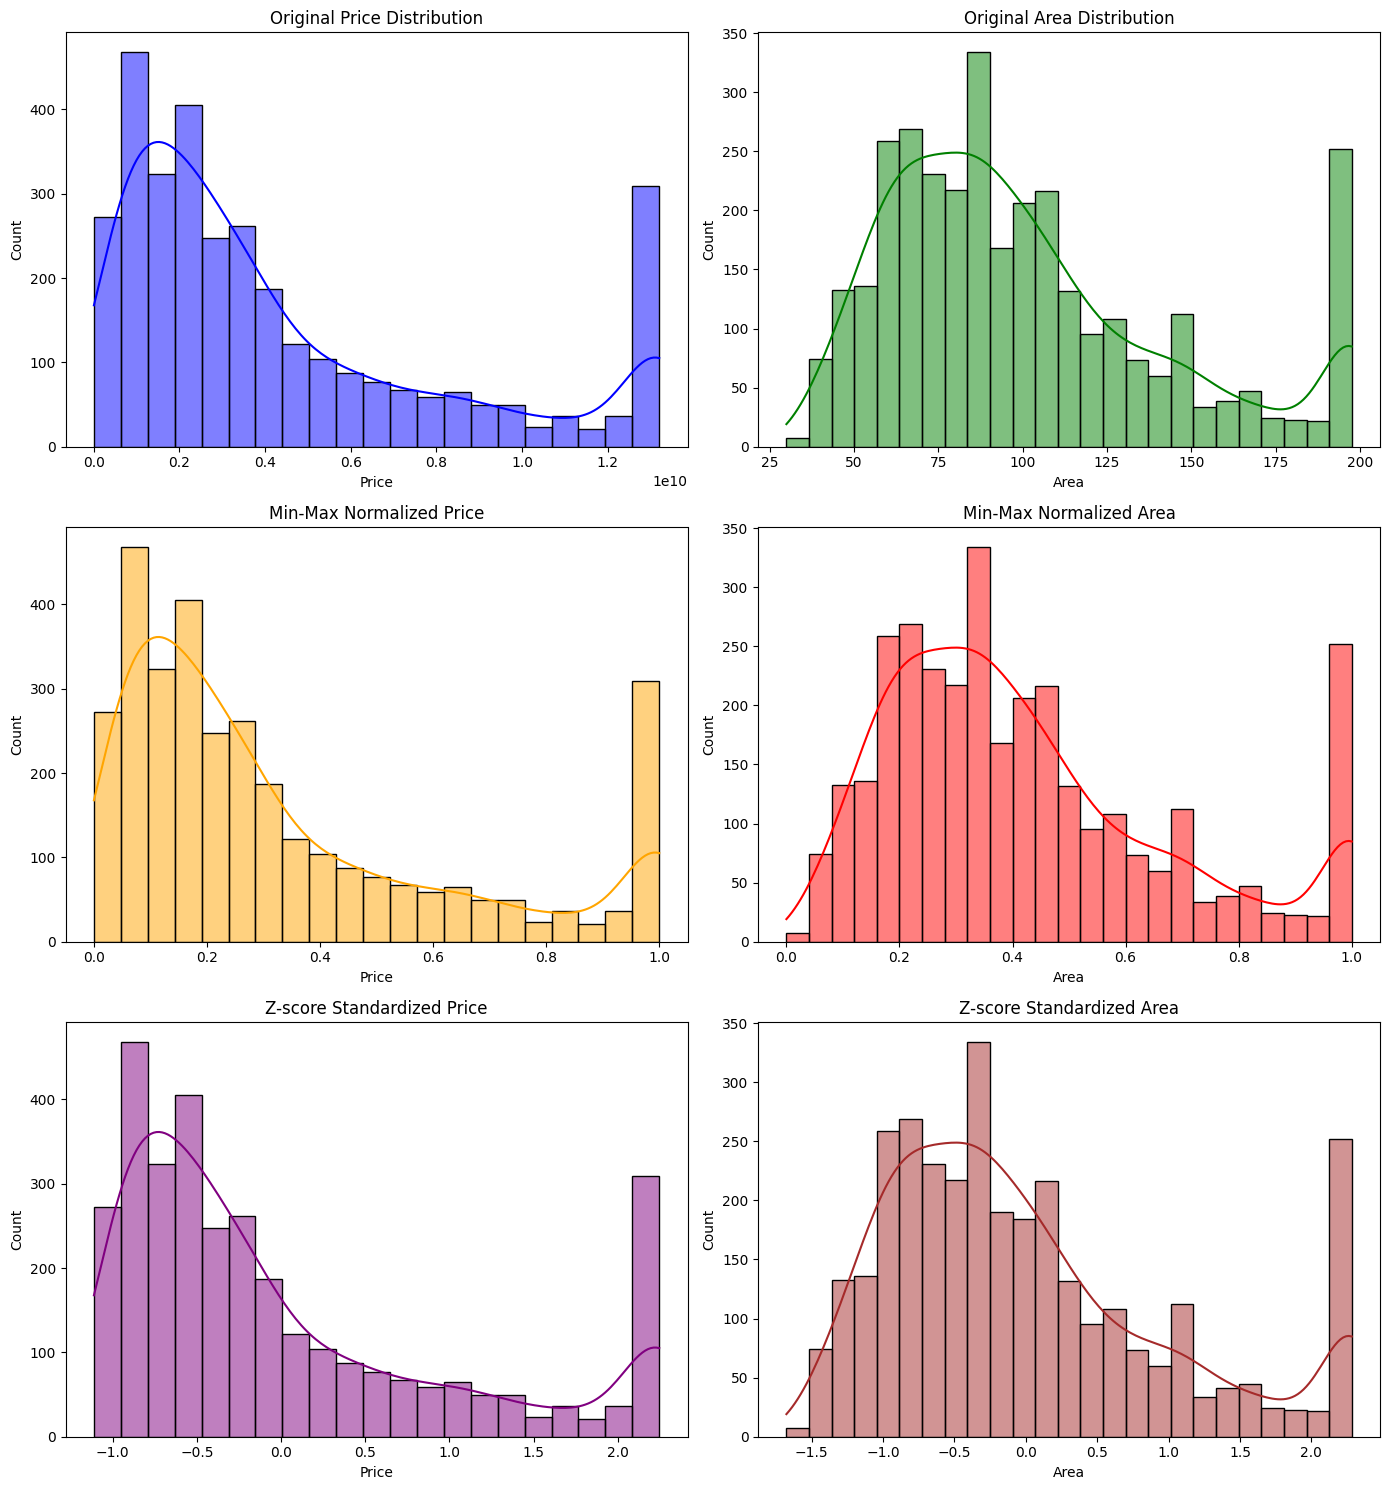

In [ ]:
# Compare distributions before and after scaling
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# Original Histograms
sns.histplot(df_new['Price'], ax=axes[0, 0], kde=True, color='blue')
axes[0, 0].set_title('Original Price Distribution')
sns.histplot(df_new['Area'], ax=axes[0, 1], kde=True, color='green')
axes[0, 1].set_title('Original Area Distribution')

# Min-Max Normalized Histograms
sns.histplot(df_new_minmax['Price'], ax=axes[1, 0], kde=True, color='orange')
axes[1, 0].set_title('Min-Max Normalized Price')
sns.histplot(df_new_minmax['Area'], ax=axes[1, 1], kde=True, color='red')
axes[1, 1].set_title('Min-Max Normalized Area')

# Z-score Standardized Histograms
sns.histplot(df_new_zscore['Price'], ax=axes[2, 0], kde=True, color='purple')
axes[2, 0].set_title('Z-score Standardized Price')
sns.histplot(df_new_zscore['Area'], ax=axes[2, 1], kde=True, color='brown')
axes[2, 1].set_title('Z-score Standardized Area')

plt.tight_layout()
plt.show()

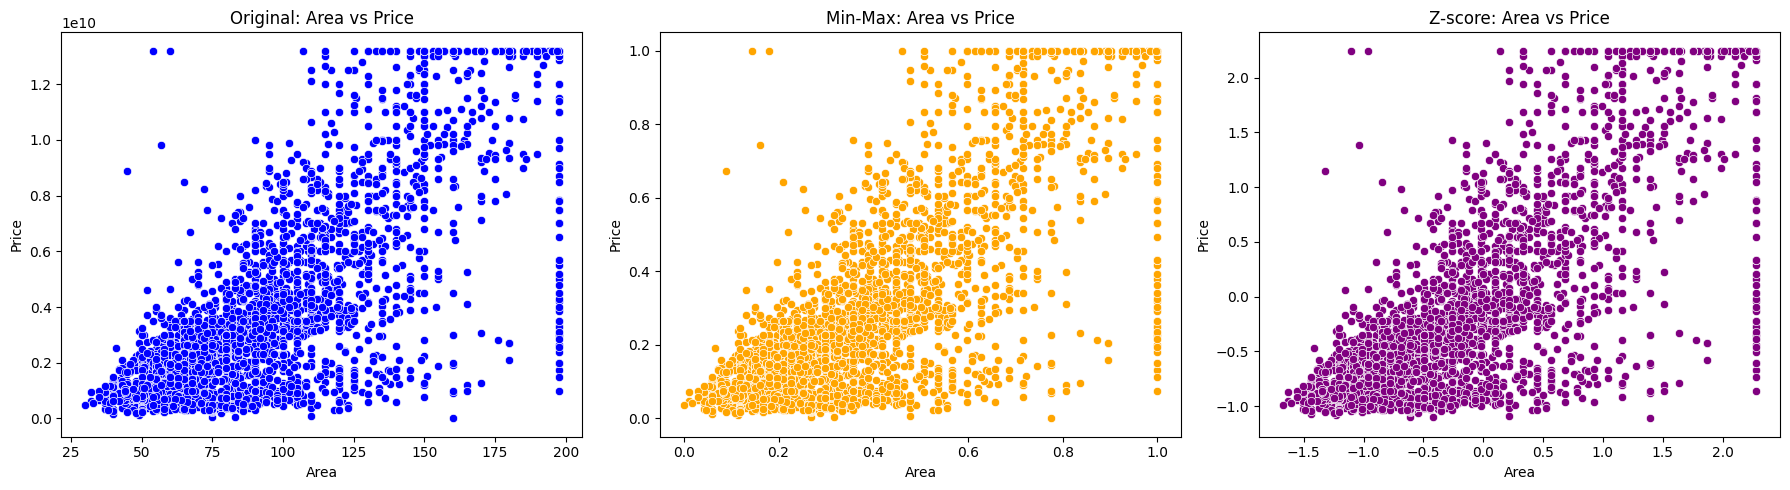

In [ ]:
# Compare relationships before and after scaling
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original relationship
sns.scatterplot(data=df_new, x='Area', y='Price', ax=axes[0], color='blue')
axes[0].set_title('Original: Area vs Price')

# Min-Max scaling relationship
sns.scatterplot(data=df_new_minmax, x='Area', y='Price', ax=axes[1], color='orange')
axes[1].set_title('Min-Max: Area vs Price')

# Z-score standardization relationship
sns.scatterplot(data=df_new_zscore, x='Area', y='Price', ax=axes[2], color='purple')
axes[2].set_title('Z-score: Area vs Price')

plt.tight_layout()
plt.show()

New Dataset


## Processing the New Dataset: `dirty_housing_data.csv`

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Load the new dataset
try:
    df_dirty = pd.read_csv('/content/dirty_housing_data.csv')
    print("Dataset loaded successfully!")
    print(f"Dataset Shape: {df_dirty.shape}")
    print("Columns:", df_dirty.columns.tolist())
    display(df_dirty.head())
except Exception as e:
    print("Error loading dataset:", e)

Dataset loaded successfully!
Dataset Shape: (1565, 26)
Columns: ['Id', 'Neighborhood', 'HouseStyle', 'Foundation', 'RoofStyle', 'SaleType', 'CentralAir', 'LotArea', 'LivingArea', 'BasementArea', 'GarageArea', 'LotFrontage', 'DistanceToCity_km', 'Bedrooms', 'Bathrooms', 'TotalRooms', 'Fireplaces', 'GarageCars', 'YearBuilt', 'YearSold', 'OverallQual', 'OverallCond', 'KitchenQual', 'HeatingQC', 'ExteriorQual', 'SalePrice']


,Id,Neighborhood,HouseStyle,Foundation,RoofStyle,SaleType,CentralAir,LotArea,LivingArea,BasementArea,...,Fireplaces,GarageCars,YearBuilt,YearSold,OverallQual,OverallCond,KitchenQual,HeatingQC,ExteriorQual,SalePrice
0,211,Old_Town,1Story,Stone,Gable,Conventional,Y,11836.0,1604.0,1212.0,...,2.0,4,1934.0,2023,9,4.0,Average,NaN,Avg,292196.0
1,1014,INDUSTRIAL_EDGE,1Story,BrickTile,Gambrel,Conventional,Y,15762.0,1954.0,0.0,...,1.0,2,2015.0,2020,3,6.0,Fair,Average,Good,200963.0
2,761,Old_Town,Bungalow,Concrete,Gable,ForeclosureSale,Y,7486.0,1698.0,416.0,...,0.0,2,NaN,2018,6,6.0,TA,Average,Average,208376.0
3,72,Suburb_South,Duplex,Concrete,Gambrel,Conventional,N,9484.0,1811.0,790.0,...,0.0,4,1935.0,2023,4,7.0,Average,Average,Average,255277.0
4,903,Downtown,2Story,BrickTile,Gable,Conventional,Y,4304.0,1467.0,996.0,...,1.0,1,1945.0,2019,5,6.0,Good,Good,Average,290724.0


### Data Cleaning: Duplicates, Missing Values, and Outliers for `dirty_housing_data.csv`

In [13]:
# 1. Handle Duplicates
df_dirty = df_dirty.drop_duplicates()
print(f"Shape after removing duplicates: {df_dirty.shape}")

# Map columns dynamically using correct column names in dirty_housing_data.csv
# Price is 'SalePrice', and we can use 'LotArea' or 'LivingArea' for Area
price_col = 'SalePrice'
area_col = 'LotArea'

# 2. Handle Missing Values
if price_col in df_dirty.columns:
    df_dirty[price_col] = df_dirty[price_col].fillna(df_dirty[price_col].median())
if area_col in df_dirty.columns:
    df_dirty[area_col] = df_dirty[area_col].fillna(df_dirty[area_col].median())

# 3. Handle Outliers using IQR method for continuous variables
for col in [price_col, area_col]:
    if col in df_dirty.columns:
        Q1 = df_dirty[col].quantile(0.25)
        Q3 = df_dirty[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_dirty[col] = np.clip(df_dirty[col], lower_bound, upper_bound)

print(f"Missing values and outliers handled successfully for '{price_col}' and '{area_col}'.")

Shape after removing duplicates: (1524, 26)
Missing values and outliers handled successfully for 'SalePrice' and 'LotArea'.


### Feature Encoding & Discrete/Nominal Visualizations for `dirty_housing_data.csv`

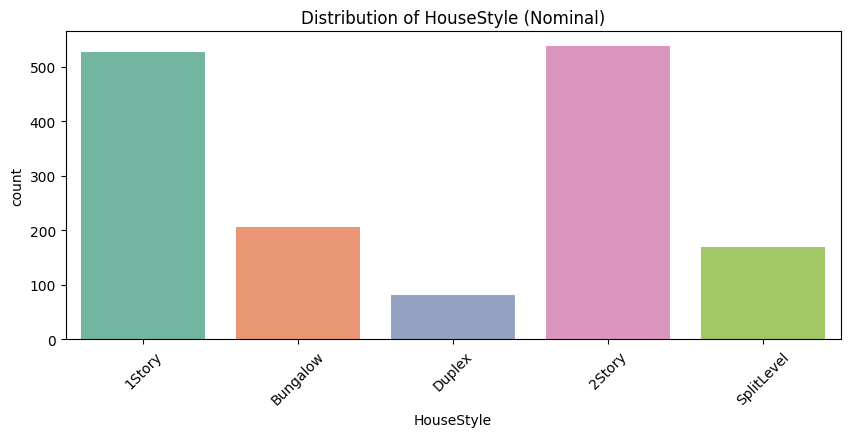

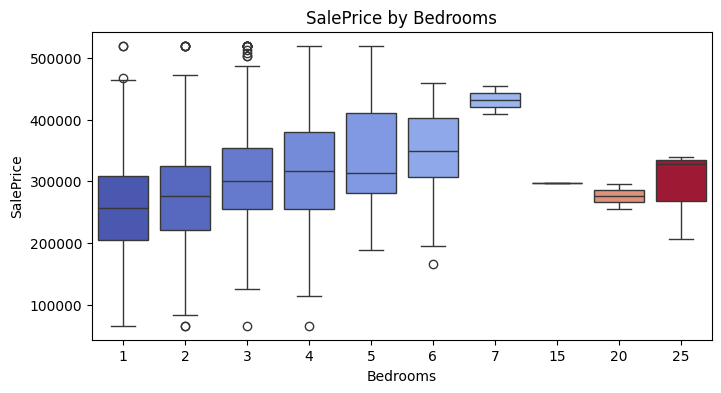

In [8]:
# Bar plot for Nominal/Categorical Variable (using 'HouseStyle' as it exists in this dataset)
nominal_col = 'HouseStyle'

if nominal_col in df_dirty.columns:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df_dirty, x=nominal_col, palette='Set2', hue=nominal_col, legend=False)
    plt.title(f'Distribution of {nominal_col} (Nominal)')
    plt.xticks(rotation=45)
    plt.show()
else:
    print(f"{nominal_col} column not found.")

# Box plot of price by discrete category (using 'Bedrooms' as it exists in this dataset)
discrete_col = 'Bedrooms'

if discrete_col in df_dirty.columns and price_col in df_dirty.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_dirty, x=discrete_col, y=price_col, palette='coolwarm', hue=discrete_col, legend=False)
    plt.title(f'{price_col} by {discrete_col}')
    plt.show()
else:
    print(f"Could not create box plot for {price_col} by {discrete_col}.")

### Scaling: Min-Max Normalization and Z-score Standardization

In [9]:
# Apply scaling to continuous variables
scaling_cols = [area_col, price_col]

# Min-Max Normalization
min_max_scaler = MinMaxScaler()
df_dirty_minmax = df_dirty.copy()
df_dirty_minmax[scaling_cols] = min_max_scaler.fit_transform(df_dirty[scaling_cols])

# Z-score Standardization
std_scaler = StandardScaler()
df_dirty_zscore = df_dirty.copy()
df_dirty_zscore[scaling_cols] = std_scaler.fit_transform(df_dirty[scaling_cols])

print("Min-Max Normalization and Z-score Standardization completed successfully.")

Min-Max Normalization and Z-score Standardization completed successfully.


### Comparing Data Distributions (Before vs. After Scaling)

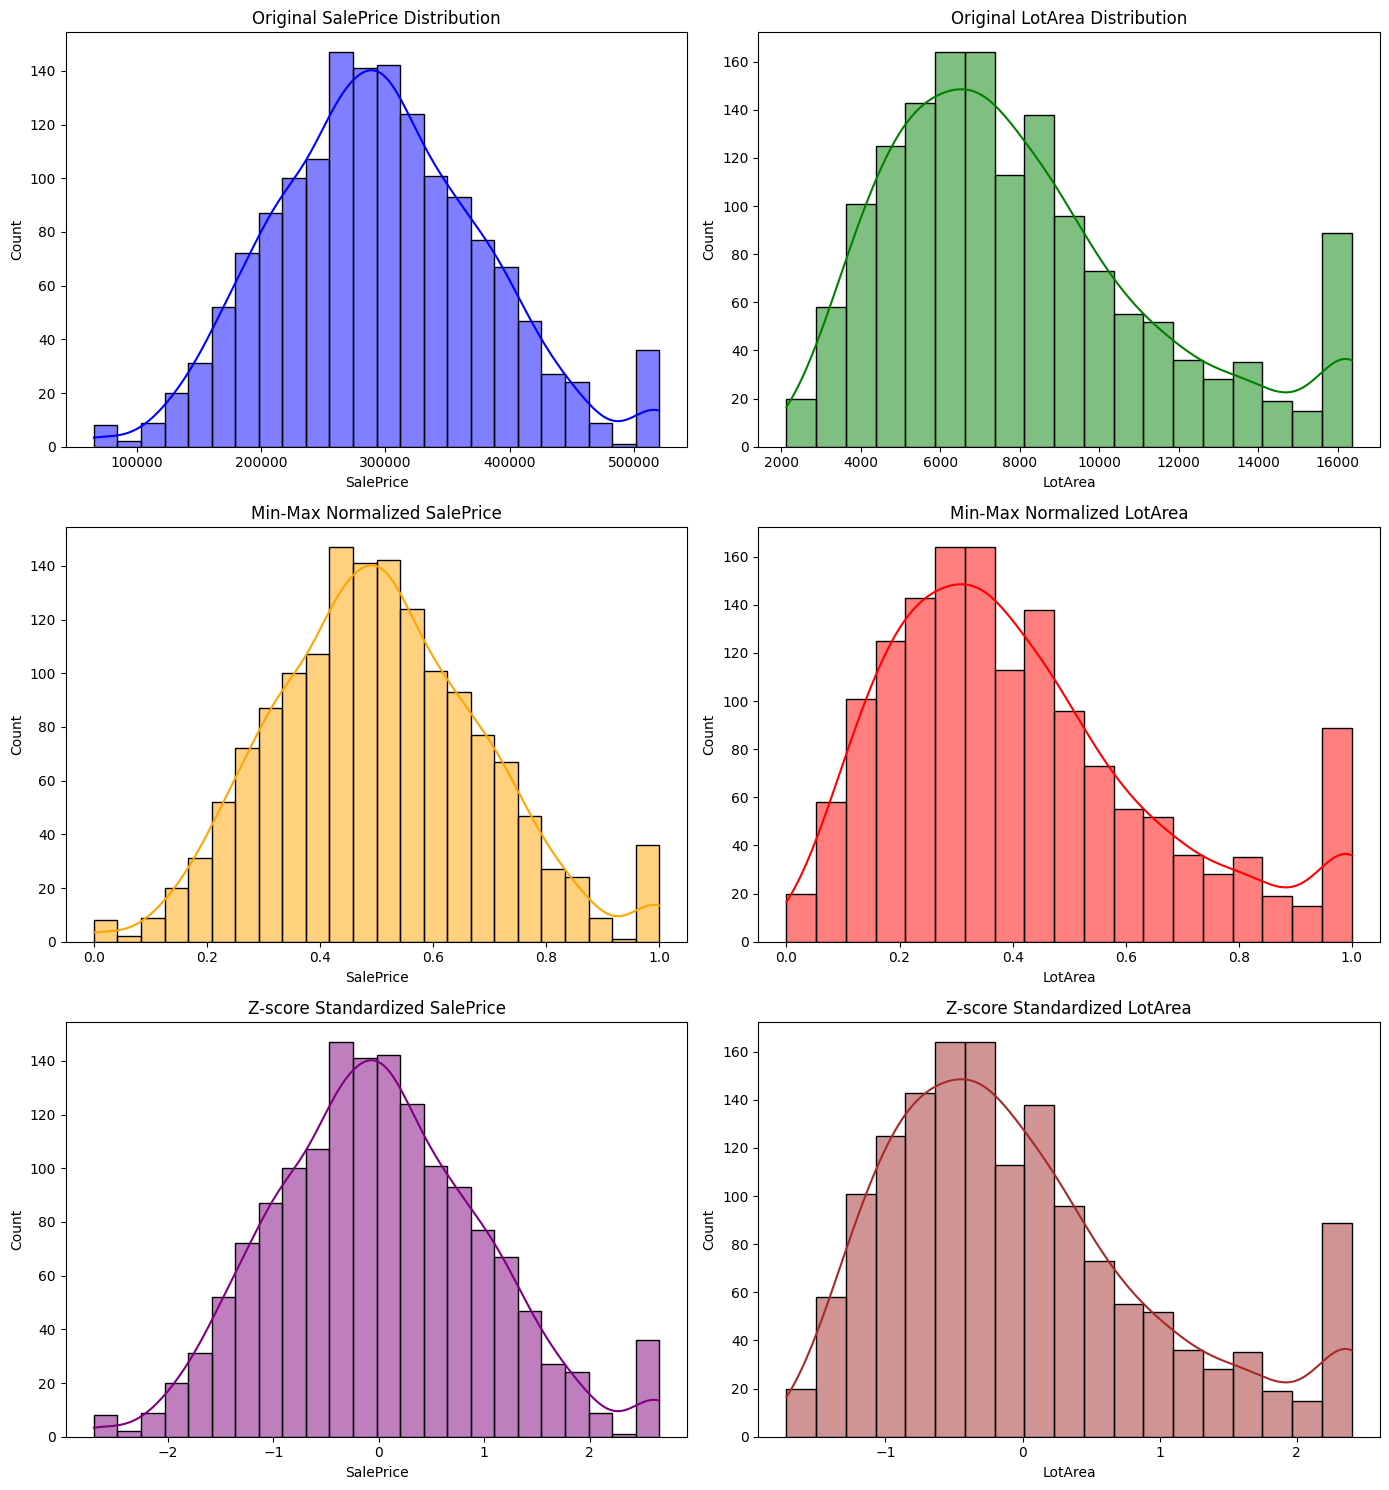

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# Original Histograms
sns.histplot(df_dirty[price_col], ax=axes[0, 0], kde=True, color='blue')
axes[0, 0].set_title(f'Original {price_col} Distribution')
sns.histplot(df_dirty[area_col], ax=axes[0, 1], kde=True, color='green')
axes[0, 1].set_title(f'Original {area_col} Distribution')

# Min-Max Normalized Histograms
sns.histplot(df_dirty_minmax[price_col], ax=axes[1, 0], kde=True, color='orange')
axes[1, 0].set_title(f'Min-Max Normalized {price_col}')
sns.histplot(df_dirty_minmax[area_col], ax=axes[1, 1], kde=True, color='red')
axes[1, 1].set_title(f'Min-Max Normalized {area_col}')

# Z-score Standardized Histograms
sns.histplot(df_dirty_zscore[price_col], ax=axes[2, 0], kde=True, color='purple')
axes[2, 0].set_title(f'Z-score Standardized {price_col}')
sns.histplot(df_dirty_zscore[area_col], ax=axes[2, 1], kde=True, color='brown')
axes[2, 1].set_title(f'Z-score Standardized {area_col}')

plt.tight_layout()
plt.show()

### Comparing Relationships (Scatter Plots Before vs. After Scaling)

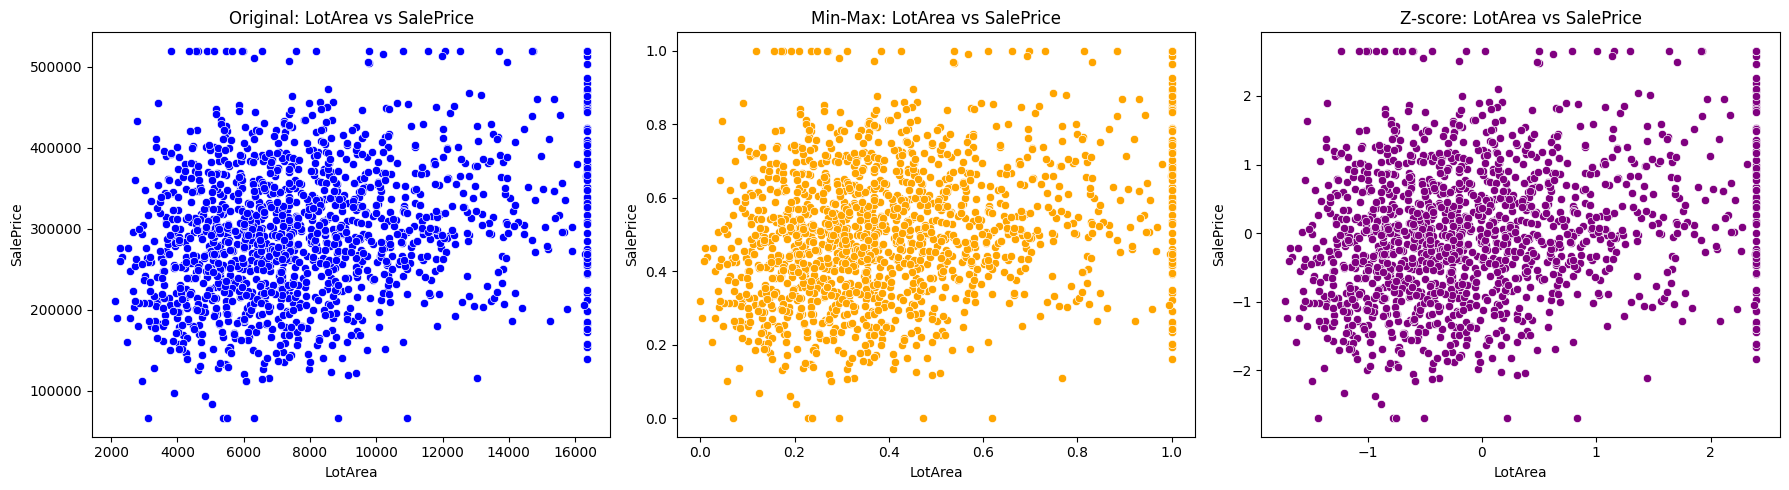

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original relationship
sns.scatterplot(data=df_dirty, x=area_col, y=price_col, ax=axes[0], color='blue')
axes[0].set_title(f'Original: {area_col} vs {price_col}')

# Min-Max scaling relationship
sns.scatterplot(data=df_dirty_minmax, x=area_col, y=price_col, ax=axes[1], color='orange')
axes[1].set_title(f'Min-Max: {area_col} vs {price_col}')

# Z-score standardization relationship
sns.scatterplot(data=df_dirty_zscore, x=area_col, y=price_col, ax=axes[2], color='purple')
axes[2].set_title(f'Z-score: {area_col} vs {price_col}')

plt.tight_layout()
plt.show()